# Skewes' number: when does $\pi(x)$ overtake $\operatorname{Li}(x)$?

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapter "A view of $|\operatorname{Li}(X) - \pi(X)|$".*

For every $x$ anyone has ever computed, $\operatorname{Li}(x)$ is larger than $\pi(x)$. The book warns:

> Data such as this graph can be revealing and misleading at the same time. For example, the volatile blue graph (of $\operatorname{Li}(X)-\pi(X)$) *seems* to be roughly sandwiched between two rising functions, but this will not continue for all values of $X$. The Cambridge University mathematician, John Edensor Littlewood … proved in 1914 that there *exists* a real number $X$ for which the quantity $\operatorname{Li}(X)-\pi(X)$ vanishes, and then for slightly larger $X$ crosses over into negative values. … That "first" $X$ for which $\operatorname{Li}(X) =\pi(X)$ is called **Skewes Number** in honor of the South African mathematician (a student of Littlewood) Stanley Skewes, who (in 1933) gave the first—fearfully large—upper bound for that number (conditional on the Riemann Hypothesis!).

and locates it, as of 2016, in the range
$$10^{14} \;\le\; \text{Skewes Number} \;<\; 10^{317}.$$
(The lower bound has since been raised: $\pi(x) < \operatorname{li}(x)$ for all $2 \le x \le 10^{19}$.)

In this notebook you will compute with numbers near $10^{316}$, where ordinary floating point fails, and then see **why** the crossing happens there, using the zeros of $\zeta(s)$.

## 1. Numbers near $10^{316}$

The worksheet behind the book checked where the upper bound comes from: the first crossing is believed to lie near $x = e^{727.951346801\ldots}$. Ordinary double-precision numbers stop at about $1.8 \times 10^{308}$, so they cannot even hold such an $x$:

In [1]:
import math
try:
    print(math.exp(727.951346801))
except OverflowError as e:
    print('a double overflows:', e)
print('largest double:', float.fromhex('0x1.fffffffffffffp+1023'))

a double overflows: math range error
largest double: 1.7976931348623157e+308


Sage's `RealField(prec)` gives real numbers with `prec` bits of precision and an enormous exponent range, so the computation is no problem:

In [2]:
R = RealField(200)
x = exp(R(727.951346801))
print('x = e^727.951346801 =', x)
print('log10(x) =', log(x) / log(R(10)))
print('10^316.145253009715 =', R(10)^R(316.145253009715))

x = e^727.951346801 = 1.3971820893116261489402094877905302922671769174718730555425e316
log10(x) = 316.14525300971468972010402889342179545884773955096089018695
10^316.145253009715 = 1.3971820893126243599039422359547338801666619059798603703117e316


## 2. Why the crossing happens: the zeros at work

Riemann's explicit formula expresses $\pi(x) - \operatorname{li}(x)$ through the zeros $\rho = \tfrac12 + i\gamma$ of $\zeta(s)$. Assuming the Riemann Hypothesis and writing $u = \log x$, it says, roughly,
$$\frac{\pi(x) - \operatorname{li}(x)}{\sqrt{x}/\log x} \;\approx\; -1 \;-\; \sum_{\gamma > 0} \frac{2\left(\tfrac12\cos(\gamma u) + \gamma \sin(\gamma u)\right)}{\tfrac14 + \gamma^2}.$$

* The constant $-1$ comes from the squares of primes: it is the bias $\tfrac12\operatorname{li}(\sqrt{x})$ that keeps $\pi(x)$ below $\operatorname{li}(x)$ (see *How good is $\operatorname{Li}(x)$?*).
* Each zero contributes a wave in $u = \log x$, with frequency $\gamma$ and amplitude about $2/\gamma$.

For $\pi(x)$ to overtake $\operatorname{li}(x)$ the waves must line up well enough to beat the bias of $-1$. Since the amplitudes are small and the frequencies $\gamma$ look random, that takes a very long time: the first time they line up well enough is near $u \approx 727.95$, that is $x \approx 1.397 \times 10^{316}$. Computations by Bays and Hudson (2000), using about a million zeros and refined since, show that $\pi(x) > \operatorname{li}(x)$ for many $x$ in a narrow window there.

We use the first $1000$ zeros, read from a file beside this notebook (computed with mpmath; Sage's `zeta_zeros()` gives the same numbers). Choose how many to use, and where to look.

In [3]:
import numpy as np
GAMMA = np.array([float(line) for line in open('zeta_zeros_1000.txt') if not line.startswith('#')])
print(len(GAMMA), 'zeros; the first three:', GAMMA[:3])

def wave_sum(u, zeros):
    "The truncated explicit formula: -1 minus the waves of the first `zeros` zeros, at the points u = log x."
    g = GAMMA[:zeros]
    U = np.outer(u, g)
    return -1 - (2 * (0.5 * np.cos(U) + g * np.sin(U)) / (0.25 + g**2)).sum(axis=1)

1000 zeros; the first three: [14.13472514 21.02203964 25.01085758]


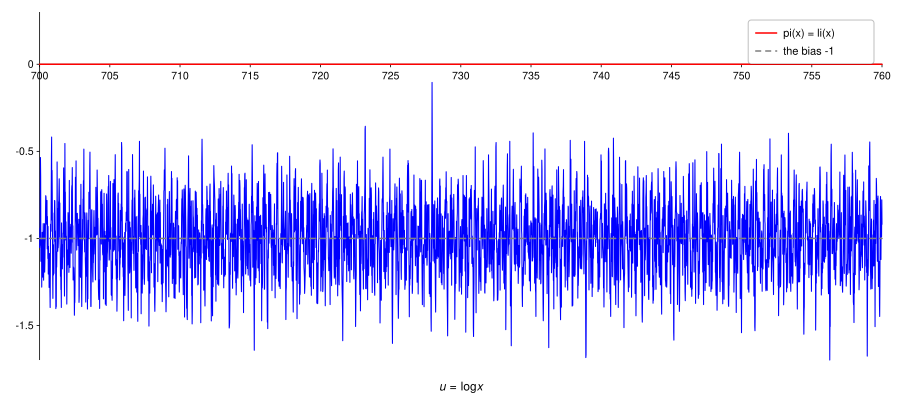

highest point: -0.1044 at u = 727.95199, x = 1.3980782e316


In [4]:
WINDOWS = {
    'u from 0 to 1000 (x up to e^1000)': (5, 1000),
    'u from 700 to 760': (700, 760),
    'u from 727.9 to 728.0 (the crossing)': (727.9, 728.0),
}

@interact
def zeros_at_work(zeros=selector([10, 50, 100, 200, 500, 1000], default=200, label='zeros used'),
                  where=selector(list(WINDOWS), default='u from 700 to 760', label='where')):
    a, b = WINDOWS[where]
    u = np.linspace(a, b, 4000)
    s = wave_sum(u, zeros)
    g = list_plot(list(zip(u, s)), plotjoined=True, color='blue', thickness=0.7)
    g += line([(a, 0), (b, 0)], color='red', legend_label='pi(x) = li(x)')
    g += line([(a, -1), (b, -1)], color='gray', linestyle='--', legend_label='the bias -1')
    show(g, axes_labels=['$u = \\log x$', ''], figsize=[9, 4], ymax=0.3)
    i = int(np.argmax(s))
    print('highest point: %.4f at u = %.5f, x = %s' % (s[i], u[i], RealField(30)(exp(RealField(60)(u[i])))))

With more zeros the peak near $u \approx 727.95$ climbs towards $0$; the sum converges very slowly, and it takes far more zeros than we use here to push it above $0$. Elsewhere in the range shown it stays near the bias $-1$.

## Things to try

1. Find the highest point of the sum for $u$ between $0$ and $700$ with $1000$ zeros. How close does it come to $0$, and where?
2. Replace the bias $-1$ by $0$ (no prime squares). How often would $\pi(x)$ be ahead of $\operatorname{li}(x)$ then? (Rubinstein and Sarnak showed that, with the bias, $\pi(x) > \operatorname{li}(x)$ for a logarithmic proportion of only about $0.00000026$ of all $x$.)
3. Use `RealField(300)` to compute $\operatorname{li}(x)$ at $x = e^{727.95}$ with mpmath (`mpmath.li`), and compare its size with $\sqrt{x}/\log x$: how big a "wave" is needed?

---
*Adapted and greatly expanded from the worksheets that produced figures for* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. The zeros in `zeta_zeros_1000.txt` were computed with mpmath. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*